# Full-trace pooled comparison: M−N versus E−N

Use **all observations** in `data/features/recomputed/fulltrace/batch_004_enm`, without node pairing or averaging. N = neutral, M = mechanical, E = emotional/anxiety.

The primary question compares signed mean differences: **(M−N) − (E−N) = M−E**. Thus the direct test is an independent-sample Welch test of mechanical versus emotional means. Testing M−N and E−N separately and comparing their significance would not answer this question.

Also report each condition's mean difference from neutral and the secondary absolute-distance contrast **|mean(M)−mean(N)| − |mean(E)−mean(N)|**. Bootstrap intervals resample each condition independently and reuse the same resampled neutral mean in both differences.

This pooled analysis treats traces as independent, as requested. Repeated observations from the same node can violate that assumption; uncertainty may be understated. Nonsignificance does not establish equivalence. Equivalence would require a prespecified scientifically meaningful margin. Results concern measured hardware features, not subjective experience.

In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from IPython.display import display

BASE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/features/recomputed/fulltrace').is_dir())
INPUT_DIR = BASE_DIR/'data/features/recomputed/fulltrace/batch_004_enm'
RESULTS_DIR = BASE_DIR/'results/analysis_MECHA_pooled'
RESULTS_DIR.mkdir(exist_ok=True)
CONDITIONS = ['neutral', 'mechanical', 'emotional']
FEATURES = ['core_power.throttle__'+x for x in ['mean_rate','variance','spectral_entropy','slope']]
RATIO = 'core_power.throttle__per_cycle'
FEATURES.append(RATIO)
SHORT = {f:f.split('__')[-1] for f in FEATURES}
SHORT[RATIO] = 'throttle_per_cycle'
COLORS = ['#777777','#268C81','#C44E52']


## Load and validate all individual traces
The combined file is verified but not counted as extra observations. Node IDs are retained only as provenance.

In [2]:
paths = sorted(p for p in INPUT_DIR.glob('*_whole.csv') if p.name != 'all_whole.csv')
if not paths: raise ValueError('No individual trace CSVs found')
frames = []
for path in paths:
    row = pd.read_csv(path, dtype={'run_label':str,'condition':str})
    if len(row)!=1 or row.run_label.iloc[0]!=path.name.removesuffix('_whole.csv'):
        raise ValueError(f'Invalid trace row: {path}')
    row['source_file'] = str(path.relative_to(BASE_DIR))
    frames.append(row)
df = pd.concat(frames, ignore_index=True)
if df.run_label.duplicated().any(): raise ValueError('Duplicate run labels')
required = ['mode','n_prompts',*FEATURES[:-1],'cycles__mean_rate']
if any(f not in df for f in required): raise ValueError('Missing required columns')
if set(df.condition)!=set(CONDITIONS) or not df['mode'].eq('whole_trace').all():
    raise ValueError('Unexpected conditions or modes')
parsed = df.run_label.str.extract(r'^(?P<node>\d+)_(?P<code>[NME])_(?P<repeat>\d+)$')
if parsed.isna().any().any(): raise ValueError('Unrecognized run label')
if not parsed.code.map({'N':'neutral','M':'mechanical','E':'emotional'}).eq(df.condition).all():
    raise ValueError('Condition metadata disagrees with run label')
aggregate = INPUT_DIR/'all_whole.csv'
if aggregate.exists():
    pd.testing.assert_frame_equal(df.drop(columns='source_file').sort_values('run_label').reset_index(drop=True),
        pd.read_csv(aggregate,dtype={'run_label':str,'condition':str}).sort_values('run_label').reset_index(drop=True),check_dtype=False)
df['node'] = parsed.node
rates = df[['core_power.throttle__mean_rate','cycles__mean_rate']].to_numpy(float)
if not np.isfinite(rates).all() or (rates[:,0]<0).any() or (rates[:,1]<=0).any():
    raise ValueError('Invalid throttle/cycle rates')
df[RATIO] = rates[:,0]/rates[:,1]
if not np.isfinite(df[FEATURES].to_numpy(float)).all(): raise ValueError('Nonfinite features')
counts = df.condition.value_counts().reindex(CONDITIONS)
if (counts<2).any(): raise ValueError('Need at least two observations per condition')
print('All observations, without node pairing:')
display(counts)
display(df.groupby('condition')[FEATURES].mean().reindex(CONDITIONS).rename(columns=SHORT))
df.to_csv(RESULTS_DIR/'input_traces.csv',index=False)


All observations, without node pairing:


condition
neutral       5
mechanical    5
emotional     5
Name: count, dtype: int64

,mean_rate,variance,spectral_entropy,slope,throttle_per_cycle
condition,,,,,
neutral,1.247645e+09,3.583765e+13,0.797010,11.082079,0.009900
mechanical,1.275103e+09,3.451050e+13,0.818327,11.172987,0.010115
emotional,1.283927e+09,3.507179e+13,0.817085,9.741675,0.010201


## Pooled contrasts and uncertainty

Use the original four throttle features plus throttle per CPU cycle. The ratio is supplementary and does not control all workload differences. Primary Welch p-values receive Bonferroni correction across five features. Pairwise M−N and E−N tests are supplementary and corrected together across ten comparisons. Bootstrap percentile intervals (20,000 draws, fixed seed) are unadjusted descriptive 95% intervals, not equivalence tests. Absolute-distance intervals are exploratory, particularly when a condition mean is close to neutral.

In [3]:
from scipy.stats import ttest_ind
rng = np.random.default_rng(42)
B = 20000
rows=[]
bootstrap_rows=[]
for feature in FEATURES:
    groups={c:df.loc[df.condition.eq(c),feature].to_numpy(float) for c in CONDITIONS}
    means={c:a.mean() for c,a in groups.items()}
    boots={c:a[rng.integers(0,len(a),size=(B,len(a)))].mean(axis=1) for c,a in groups.items()}
    a=means['mechanical']-means['neutral']
    b=means['emotional']-means['neutral']
    ba=boots['mechanical']-boots['neutral']
    bb=boots['emotional']-boots['neutral']
    for contrast,value,samples,left,right in [
        ('M_minus_N',a,ba,'mechanical','neutral'),
        ('E_minus_N',b,bb,'emotional','neutral'),
        ('signed_gap_M_minus_E',a-b,ba-bb,'mechanical','emotional'),
        ('absolute_distance_gap',abs(a)-abs(b),abs(ba)-abs(bb),None,None)]:
        lo,hi=np.quantile(samples,[.025,.975])
        test=ttest_ind(groups[left],groups[right],equal_var=False) if left else None
        pvalue=float(test.pvalue) if test else np.nan
        family_size=len(FEATURES) if contrast=='signed_gap_M_minus_E' else 2*len(FEATURES)
        rows.append(dict(feature=SHORT[feature],contrast=contrast,estimate=value,
            bootstrap_ci95_low=lo,bootstrap_ci95_high=hi,
            welch_p=pvalue,p_bonferroni=min(pvalue*family_size,1) if test else np.nan,
            n_neutral=len(groups['neutral']),n_mechanical=len(groups['mechanical']),n_emotional=len(groups['emotional'])))
results=pd.DataFrame(rows)
results.to_csv(RESULTS_DIR/'pooled_contrasts.csv',index=False)
primary=results[results.contrast.eq('signed_gap_M_minus_E')]
print('PRIMARY: does M−N equal E−N? Direct contrast = M−E')
display(primary)
print('Supplementary contrasts:')
display(results[~results.contrast.eq('signed_gap_M_minus_E')])


PRIMARY: does M−N equal E−N? Direct contrast = M−E


,feature,contrast,estimate,bootstrap_ci95_low,bootstrap_ci95_high,welch_p,p_bonferroni,n_neutral,n_mechanical,n_emotional
2,mean_rate,signed_gap_M_minus_E,-8.824408e+06,-3.290294e+07,1.291103e+07,0.522438,1.0,5,5,5
6,variance,signed_gap_M_minus_E,-5.612842e+11,-2.072496e+12,8.539794e+11,0.519665,1.0,5,5,5
10,spectral_entropy,signed_gap_M_minus_E,1.242535e-03,-5.288125e-03,9.021206e-03,0.771022,1.0,5,5,5
14,slope,signed_gap_M_minus_E,1.431313e+00,-2.167092e+00,5.646101e+00,0.546125,1.0,5,5,5
18,throttle_per_cycle,signed_gap_M_minus_E,-8.611830e-05,-3.225026e-04,1.276082e-04,0.521430,1.0,5,5,5


Supplementary contrasts:


,feature,contrast,estimate,bootstrap_ci95_low,bootstrap_ci95_high,welch_p,p_bonferroni,n_neutral,n_mechanical,n_emotional
0,mean_rate,M_minus_N,2.745800e+07,-2.624634e+05,5.571058e+07,0.134722,1.000000,5,5,5
1,mean_rate,E_minus_N,3.628241e+07,6.792080e+06,6.763361e+07,0.073690,0.736898,5,5,5
3,mean_rate,absolute_distance_gap,-8.824408e+06,-3.243320e+07,1.281313e+07,NaN,NaN,5,5,5
4,variance,M_minus_N,-1.327147e+12,-2.399637e+12,-2.605038e+11,0.066261,0.662611,5,5,5
5,variance,E_minus_N,-7.658625e+11,-2.045192e+12,6.306293e+11,0.353190,1.000000,5,5,5
7,variance,absolute_distance_gap,5.612842e+11,-8.644662e+11,1.800677e+12,NaN,NaN,5,5,5
8,spectral_entropy,M_minus_N,2.131704e-02,1.473550e-02,2.700622e-02,0.000355,0.003555,5,5,5
9,spectral_entropy,E_minus_N,2.007451e-02,1.145959e-02,2.691086e-02,0.002057,0.020566,5,5,5
11,spectral_entropy,absolute_distance_gap,1.242535e-03,-5.288125e-03,9.021206e-03,NaN,NaN,5,5,5
12,slope,M_minus_N,9.090823e-02,-4.744748e+00,5.159372e+00,0.975051,1.000000,5,5,5


## All-observation distributions and differences from neutral
Points are individual traces; bars in the lower panels mark bootstrap 95% intervals. No node connections or matching are used.

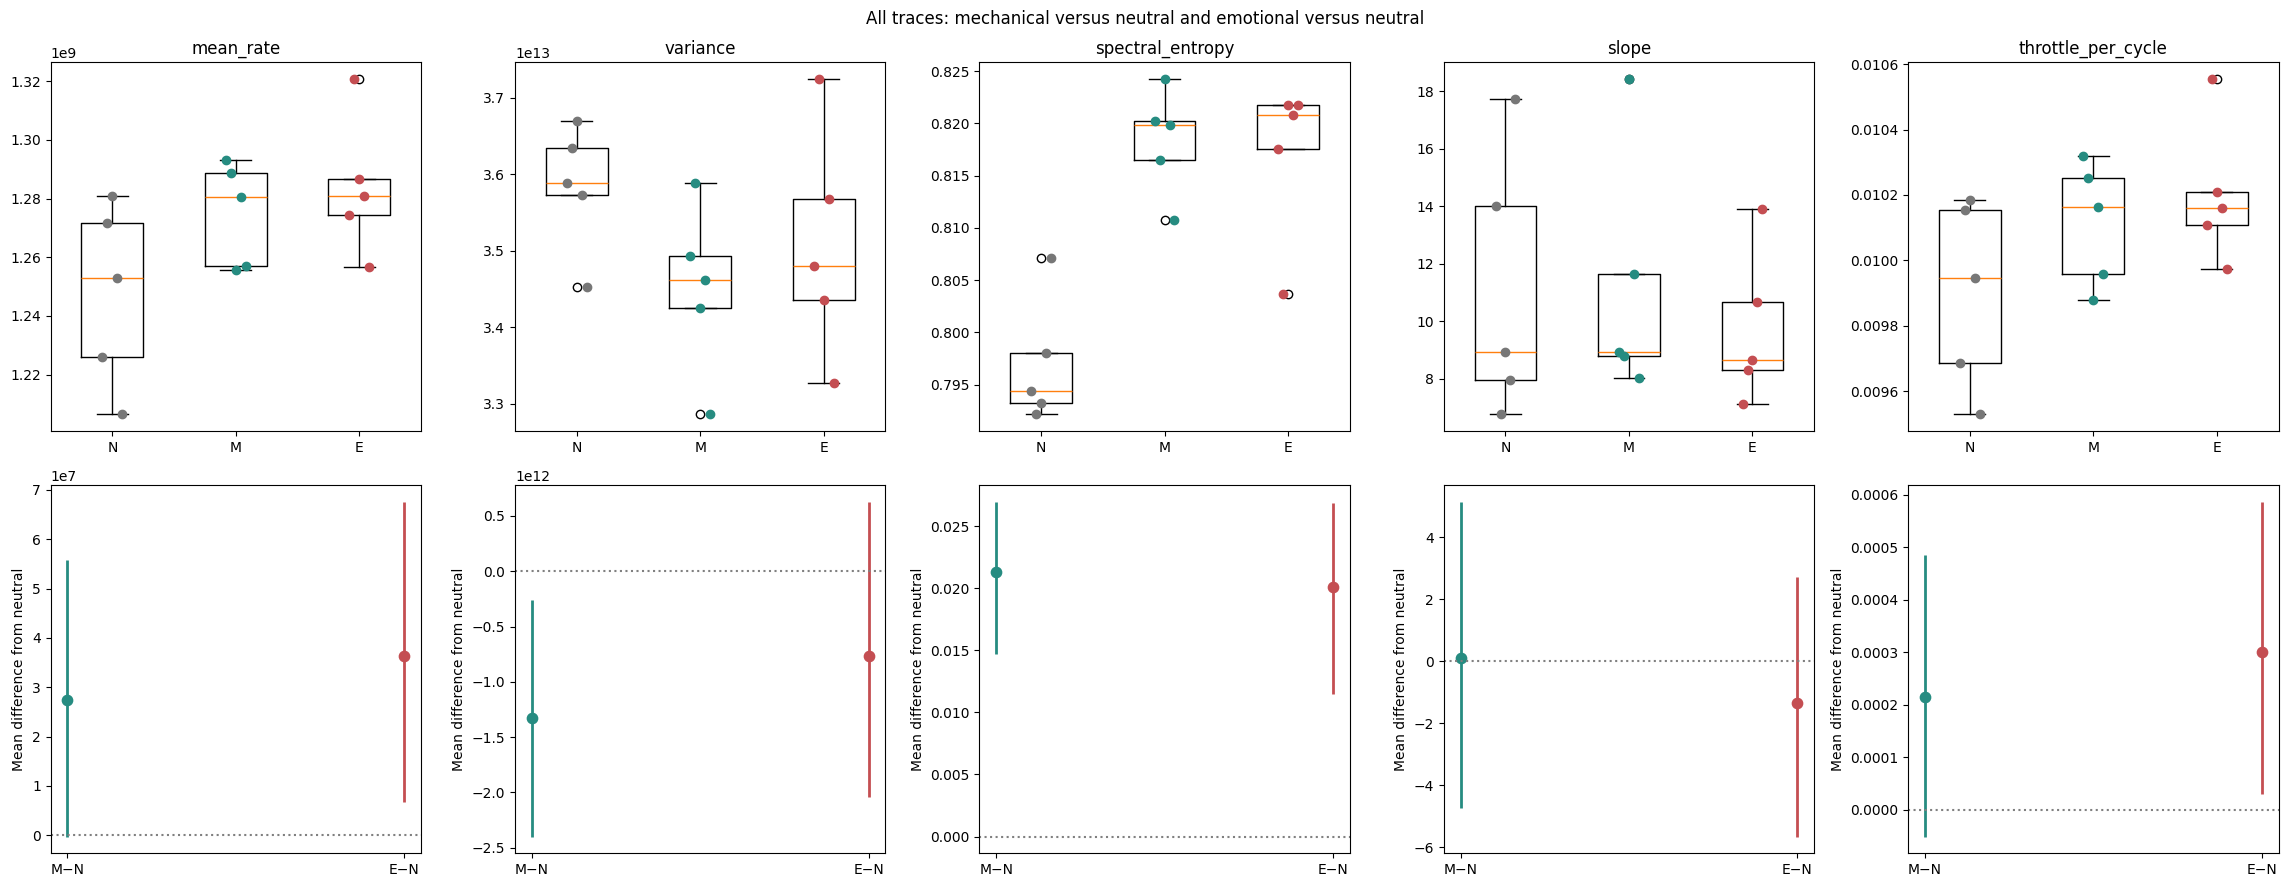

In [4]:
fig,axes=plt.subplots(2,len(FEATURES),figsize=(23,9),squeeze=False)
for j,feature in enumerate(FEATURES):
    ax=axes[0,j]
    groups=[df.loc[df.condition.eq(c),feature].to_numpy() for c in CONDITIONS]
    ax.boxplot(groups,positions=range(3),widths=.5)
    for k,(values,color) in enumerate(zip(groups,COLORS)):
        ax.scatter(k+np.linspace(-.08,.08,len(values)),values,color=color,zorder=3)
    ax.set_xticks(range(3),['N','M','E']); ax.set_title(SHORT[feature])
    ax=axes[1,j]
    subset=results[results.feature.eq(SHORT[feature])]
    for k,contrast in enumerate(['M_minus_N','E_minus_N']):
        row=subset[subset.contrast.eq(contrast)].iloc[0]
        ax.vlines(k,row.bootstrap_ci95_low,row.bootstrap_ci95_high,color=COLORS[k+1],lw=2)
        ax.scatter(k,row.estimate,color=COLORS[k+1],s=55)
    ax.axhline(0,color='gray',ls=':'); ax.set_xticks([0,1],['M−N','E−N'])
    ax.set_ylabel('Mean difference from neutral')
fig.suptitle('All traces: mechanical versus neutral and emotional versus neutral')
fig.tight_layout()
fig.savefig(RESULTS_DIR/'pooled_comparisons.png',dpi=160,bbox_inches='tight')
plt.show()


## Interpretation

If the signed gap is positive, mechanical lies above emotional relative to their common neutral reference; if negative, it lies below emotional. A positive absolute-distance gap means mechanical is farther from neutral than emotional is. Neither test requires mechanical to lie between neutral and emotional.

A significant primary result is evidence against equal signed mean differences under the independence assumptions. A nonsignificant result means insufficient evidence of a difference; it does not demonstrate sameness. The two baseline comparisons share a neutral group and are therefore dependent; the direct M−E test and shared-neutral bootstrap account for that algebraic dependence.

In [5]:
display(primary[['feature','estimate','bootstrap_ci95_low','bootstrap_ci95_high','welch_p','p_bonferroni']])
print('Features differing after correction:',primary.loc[primary.p_bonferroni<.05,'feature'].tolist())
print('No equivalence claim is made. All traces are treated as independent; node dependence remains a limitation.')
print('Outputs:',RESULTS_DIR)


,feature,estimate,bootstrap_ci95_low,bootstrap_ci95_high,welch_p,p_bonferroni
2,mean_rate,-8.824408e+06,-3.290294e+07,1.291103e+07,0.522438,1.0
6,variance,-5.612842e+11,-2.072496e+12,8.539794e+11,0.519665,1.0
10,spectral_entropy,1.242535e-03,-5.288125e-03,9.021206e-03,0.771022,1.0
14,slope,1.431313e+00,-2.167092e+00,5.646101e+00,0.546125,1.0
18,throttle_per_cycle,-8.611830e-05,-3.225026e-04,1.276082e-04,0.521430,1.0


Features differing after correction: []
No equivalence claim is made. All traces are treated as independent; node dependence remains a limitation.
Outputs: /Users/rsalvi/Desktop/mccviahat/dataNEW/analysis_MECHA_pooled
